f4_b = openmc.Tally()
f4_b.filters = [openmc.UniverseFilter(u4_group)]
f4_b.name = "b:Universe 4"
f4_b.scores=['flux']
tallies_group.append(f4_b)

f4_b = openmc.Tally()
f4_b.filters = [openmc.CellFilter(u4_group)]
f4_b.name = "b:Universe 4"
f4_b.scores=['flux']
tallies_group.append(f4_b)

In [7]:
settings = openmc.Settings()
settings.run_mode='fixed source'

background = openmc.IndependentSource()

source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,0,0))
source.angle = openmc.stats.Isotropic()
source.particle = 'neutron'
source.energy = openmc.stats.delta_function(1e6) # energy in eV 


# Enable photon transport
#settings.photon_transport = True 

# fluorescence photons and auger electrons enabled
#settings.atomic_relaxation = True 

settings.source = [source]
# settings.source_sampling = 

# History settings
settings.particles = 100
settings.batches = 100

In [8]:
model = openmc.model.Model(geometry, materials, settings, tallies)

In [9]:
model.export_to_xml()

/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=1.
  warn(msg, IDWarning)


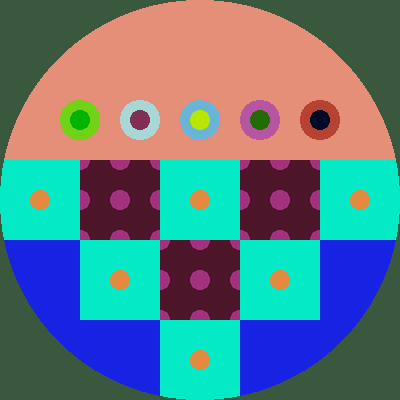

In [10]:
plots = openmc.Plots()
w = 200
origin = (0,0,0)

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

openmc.plot_inline(plots)

In [11]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [19]:
print(sp_filename)
with openmc.StatePoint(sp_filename) as sp:
    for key in (sp.tallies.keys()):
        #print(sp.tallies)
        tally_name = sp.tallies[key].name

        results = sp.get_tally(name=tally_name)
        df = results.get_pandas_dataframe()
        #print(df)

        val = df['mean'].sum()
        std = df['std. dev.'].sum()
        print(f"{tally_name} = {val} +/- {std}\n")
        if tally_name == "b:Cell 5<Universe 3":
            df = df[df['cell'].isin(c5_group) & (df["universe"].isin(u3_group))]
            val = df['mean'].sum()
            std = df['std. dev.'].sum()
            print(f"actually = {val} +/- {std}\n")
        
        

/home/jovibuca/omcmodels/mcnp_practice/mcnp_geometry_ex/statepoint.100.h5
a:Cell 5 = 14.593384736137086 +/- 0.22231802147553587

a:Cell 6 = 65.59833120957305 +/- 0.5407958718105413

a:Cell 5 + Cell 6 + Cell 3 = 88.90712388699019 +/- 0.9154477491311315

b:Cell 5<Universe 3 = 14.593384736137086 +/- 0.22231802147553587

actually = 14.593384736137086 +/- 0.22231802147553587

